# Phishing Websites : Individual Exploratory Data Analysis

**Research question:** Which features of phishing links and webpages make them harder for people to recognize?

This notebook explores only the second primary dataset: `Training Dataset.arff`. This is a classification dataset containing 30 features that describe different characteristics of a website. The values 1, 0, and -1 are labels used to represent these characteristics, where 1 indicates legitimate, 0 indicates suspicious, and -1 indicates phishing. 

However, the meaning of these values can vary depending on the specific feature. The 31st and final column, Result, tells us whether the website was actually classified as legitimate (1) or phishing (-1). Unlike the other features, the Result column can only contain 1 or -1, never 0. The purpose of this dataset is to train a machine learning model to recognize patterns among the 30 website features and learn how those characteristics relate to the final classification. By learning from websites with known results, the model can then predict whether a new website is legitimate or phishing based on its features.

In [44]:
import arff
import polars as pl
import matplotlib.pyplot as plt
import numpy as np


In [2]:
with open("../datasets/phishing-websites/Training Dataset.arff", "r") as file:
    dataset = arff.load(file)

In [3]:
# create the Polars dataframe
column_names = [attribute[0] for attribute in dataset["attributes"]]

df = pl.DataFrame(
    dataset["data"],
    schema=column_names,
    orient="row"
)

df.head()

having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""-1""","""1""","""1""","""1""","""-1""","""-1""","""-1""","""-1""","""-1""","""1""","""1""","""-1""","""1""","""-1""","""1""","""-1""","""-1""","""-1""","""0""","""1""","""1""","""1""","""1""","""-1""","""-1""","""-1""","""-1""","""1""","""1""","""-1""","""-1"""
"""1""","""1""","""1""","""1""","""1""","""-1""","""0""","""1""","""-1""","""1""","""1""","""-1""","""1""","""0""","""-1""","""-1""","""1""","""1""","""0""","""1""","""1""","""1""","""1""","""-1""","""-1""","""0""","""-1""","""1""","""1""","""1""","""-1"""
"""1""","""0""","""1""","""1""","""1""","""-1""","""-1""","""-1""","""-1""","""1""","""1""","""-1""","""1""","""0""","""-1""","""-1""","""-1""","""-1""","""0""","""1""","""1""","""1""","""1""","""1""","""-1""","""1""","""-1""","""1""","""0""","""-1""","""-1"""
"""1""","""0""","""1""","""1""","""1""","""-1""","""-1""","""-1""","""1""","""1""","""1""","""-1""","""-1""","""0""","""0""","""-1""","""1""","""1""","""0""","""1""","""1""","""1""","""1""","""-1""","""-1""","""1""","""-1""","""1""","""-1""","""1""","""-1"""
"""1""","""0""","""-1""","""1""","""1""","""-1""","""1""","""1""","""-1""","""1""","""1""","""1""","""1""","""0""","""0""","""-1""","""1""","""1""","""0""","""-1""","""1""","""-1""","""1""","""-1""","""-1""","""0""","""-1""","""1""","""1""","""1""","""1"""


In [4]:
# convert the columns to integers
df = df.with_columns(
    pl.all().cast(pl.Int64)
)

df.head()

having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1


## 1. Dataset Profiling

In [5]:
df.shape
df.glimpse()

Rows: 11055
Columns: 31
$ having_IP_Address           <i64> -1, 1, 1, 1, 1, -1, 1, 1, 1, 1
$ URL_Length                  <i64> 1, 1, 0, 0, 0, 0, 0, 0, 0, 1
$ Shortining_Service          <i64> 1, 1, 1, 1, -1, -1, -1, 1, -1, -1
$ having_At_Symbol            <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ double_slash_redirecting    <i64> -1, 1, 1, 1, 1, -1, 1, 1, 1, 1
$ Prefix_Suffix               <i64> -1, -1, -1, -1, -1, -1, -1, -1, -1, -1
$ having_Sub_Domain           <i64> -1, 0, -1, -1, 1, 1, -1, -1, 1, -1
$ SSLfinal_State              <i64> -1, 1, -1, -1, 1, 1, -1, -1, 1, 1
$ Domain_registeration_length <i64> -1, -1, -1, 1, -1, -1, 1, 1, -1, -1
$ Favicon                     <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ port                        <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ HTTPS_token                 <i64> -1, -1, -1, -1, 1, -1, 1, -1, -1, 1
$ Request_URL                 <i64> 1, 1, 1, -1, 1, 1, -1, -1, 1, 1
$ URL_of_Anchor               <i64> -1, 0, 0, 0, 0, 0, -1, 0, 0, 0
$ Links_in_tags  

In [6]:
df.null_count()

having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [7]:
df.describe()

statistic,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",0.313795,-0.633198,0.738761,0.700588,0.741474,-0.734962,0.063953,0.250927,-0.336771,0.628584,0.728268,0.675079,0.186793,-0.076526,-0.118137,-0.595749,0.63564,0.705292,0.115694,0.762099,0.913885,0.613388,0.816915,0.061239,0.377114,0.287291,-0.483673,0.721574,0.344007,0.719584,0.113885
"""std""",0.949534,0.766095,0.673998,0.713598,0.671011,0.678139,0.817518,0.911892,0.941629,0.777777,0.685324,0.737779,0.982444,0.715138,0.763973,0.759143,0.772021,0.708949,0.319872,0.64749,0.405991,0.789818,0.576784,0.998168,0.926209,0.827733,0.875289,0.692369,0.569944,0.694437,0.993539
"""min""",-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
"""25%""",-1.0,-1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0,-1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,-1.0,-1.0,0.0,-1.0,1.0,0.0,1.0,-1.0
"""50%""",1.0,-1.0,1.0,1.0,1.0,-1.0,0.0,1.0,-1.0,1.0,1.0,1.0,1.0,0.0,0.0,-1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,0.0,1.0,1.0
"""75%""",1.0,-1.0,1.0,1.0,1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,-1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
"""max""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [8]:
df.columns

['having_IP_Address',
 'URL_Length',
 'Shortining_Service',
 'having_At_Symbol',
 'double_slash_redirecting',
 'Prefix_Suffix',
 'having_Sub_Domain',
 'SSLfinal_State',
 'Domain_registeration_length',
 'Favicon',
 'port',
 'HTTPS_token',
 'Request_URL',
 'URL_of_Anchor',
 'Links_in_tags',
 'SFH',
 'Submitting_to_email',
 'Abnormal_URL',
 'Redirect',
 'on_mouseover',
 'RightClick',
 'popUpWidnow',
 'Iframe',
 'age_of_domain',
 'DNSRecord',
 'web_traffic',
 'Page_Rank',
 'Google_Index',
 'Links_pointing_to_page',
 'Statistical_report',
 'Result']

##### This is not a data error and it's just a naming issue – however some of the column names have grammatical errors. Such as `shortining_service` and `Domain_registeration_length`. Those should probably both be `Shortening_Service` and `Domain_registration_length` respectively. 

In [9]:
df = df.rename({
    "Shortining_Service": "Shortening_Service",
    "Domain_registeration_length": "Domain_registration_length",
})

In [10]:
df.group_by("Result").len().sort("Result", descending=True)

Result,len
i64,u32
1,6157
-1,4898


### Profiling + any anomalies

##### The dataset has a shape of (11055, 31), meaning it contains 11,055 website records and 31 columns. Out of those 31 columns, 30 are features and 1 is a `Result` column. All columns contain numerical values representing different website characteristics. There are no missing values in any of the columns, so we wouldn't need to handle null values before analyzing the data. 

##### Using df.describe, since these numbers represent categories rather than actual measurements, the averages and standard deviations aren't that meaningful. But you can tell from df.describe that the  `Redirect` feature only uses 0 and 1. Meaning the `Redirect` feature is never really classified as a 'phishing' feature in a website. Another thing that stands out is that the Result column contains 6,157 legitimate websites and 4,898 phishing websites, meaning there are slightly more legitimate websites in the dataset.


In [11]:
# Wanting to explore how many -1s, 0s, and 1s appear in each of the 30 features. Which one appears the most, least?

features = df.drop("Result")

feature_counts_neg1 = pl.DataFrame({"Feature": features.columns, "-1 Count": [(features[col] == -1).sum() for col in features.columns]})
feature_counts_zero = pl.DataFrame({"Feature": features.columns, "0 Count": [(features[col] == 0).sum() for col in features.columns]})
feature_counts_pos1 = pl.DataFrame({"Feature": features.columns, "1 Count": [(features[col] == 1).sum() for col in features.columns]})

print(feature_counts_neg1)
print(feature_counts_zero)
print(feature_counts_pos1)

shape: (30, 2)
┌──────────────────────────┬──────────┐
│ Feature                  ┆ -1 Count │
│ ---                      ┆ ---      │
│ str                      ┆ i64      │
╞══════════════════════════╪══════════╡
│ having_IP_Address        ┆ 3793     │
│ URL_Length               ┆ 8960     │
│ Shortening_Service       ┆ 1444     │
│ having_At_Symbol         ┆ 1655     │
│ double_slash_redirecting ┆ 1429     │
│ …                        ┆ …        │
│ web_traffic              ┆ 2655     │
│ Page_Rank                ┆ 8201     │
│ Google_Index             ┆ 1539     │
│ Links_pointing_to_page   ┆ 548      │
│ Statistical_report       ┆ 1550     │
└──────────────────────────┴──────────┘
shape: (30, 2)
┌──────────────────────────┬─────────┐
│ Feature                  ┆ 0 Count │
│ ---                      ┆ ---     │
│ str                      ┆ i64     │
╞══════════════════════════╪═════════╡
│ having_IP_Address        ┆ 0       │
│ URL_Length               ┆ 135     │
│ Shortening_Serv

In [12]:
# Most -1s
print(feature_counts_neg1.sort("-1 Count", descending=True).head(5))

# Fewest 0s
print(feature_counts_zero.sort("0 Count").head(5))

# Most 1s
print(feature_counts_pos1.sort("1 Count", descending=True).head(5))

shape: (5, 2)
┌────────────────────────────┬──────────┐
│ Feature                    ┆ -1 Count │
│ ---                        ┆ ---      │
│ str                        ┆ i64      │
╞════════════════════════════╪══════════╡
│ Prefix_Suffix              ┆ 9590     │
│ URL_Length                 ┆ 8960     │
│ SFH                        ┆ 8440     │
│ Page_Rank                  ┆ 8201     │
│ Domain_registration_length ┆ 7389     │
└────────────────────────────┴──────────┘
shape: (5, 2)
┌──────────────────────────┬─────────┐
│ Feature                  ┆ 0 Count │
│ ---                      ┆ ---     │
│ str                      ┆ i64     │
╞══════════════════════════╪═════════╡
│ having_IP_Address        ┆ 0       │
│ Shortening_Service       ┆ 0       │
│ having_At_Symbol         ┆ 0       │
│ double_slash_redirecting ┆ 0       │
│ Prefix_Suffix            ┆ 0       │
└──────────────────────────┴─────────┘
shape: (5, 2)
┌──────────────────────────┬─────────┐
│ Feature                  ┆

## Distributions

#### Note – The six graphs below include both legitimate and phishing websites, so they only tell us how frequently each feature value appears. These graphs don't tell us whether websites with certain characteristics are actually more likely to be phishing websites. To determine that, we would need to compare each feature against the Result column which will be a step after this. 

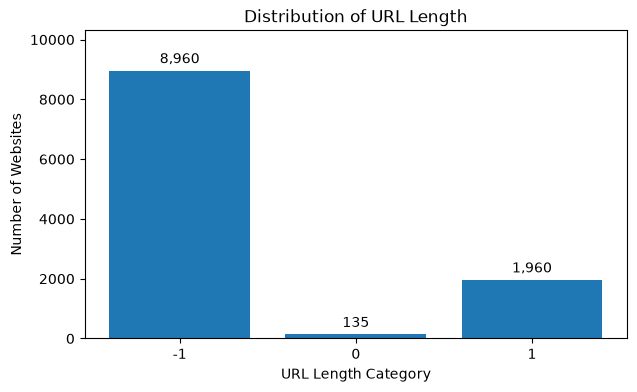

In [17]:
# Distribution of URL_Length

counts = df.group_by("URL_Length").len().sort("URL_Length")

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in counts["URL_Length"].to_list()],
    counts["len"].to_list()
)

plt.bar_label(bars, labels=[f"{int(v):,}" for v in counts["len"]], padding=3)

plt.title("Distribution of URL Length")
plt.xlabel("URL Length Category")
plt.ylabel("Number of Websites")
plt.margins(y=0.15)
plt.show()

#### The distribution of URL_Length is heavily concentrated at -1, with 8,960 websites falling into this category. Meanwhile, 1,960 websites have a value of 1, and only 135 have a value of 0. The mode is -1, and the distribution is very unbalanced, with significantly more websites having phishing-associated URL lengths than legitimate or suspicious ones. This is interesting for our research question because it suggests that URL length characteristics associated with phishing are fairly common across the dataset, although this doesn't necessarily mean all those websites are actually phishing.

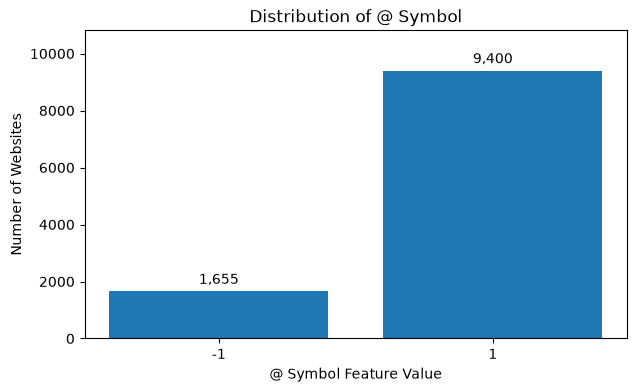

In [28]:

# Distribution of having_At_Symbol

values = [-1, 1]
counts = [df.filter(pl.col("having_At_Symbol") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of @ Symbol")
plt.xlabel("@ Symbol Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()


#### The distribution of having_At_Symbol is heavily concentrated at 1, with 9,400 websites in this category compared to only 1,655 at -1. The mode is 1, meaning the majority of websites do not have an @ symbol in their URL. This feature is intentionally binary, meaning it only allows values of -1 and 1, so there is no 0 (suspicious) category. The distribution is very unbalanced, with websites that don't have an @ symbol appearing much more frequently than those that do. Overall, this shows that using an @ symbol in a URL is relatively uncommon in this dataset.

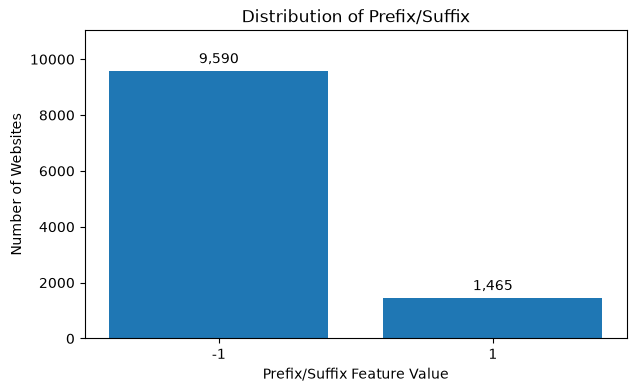

In [33]:
# Distribution of Prefix_Suffix

values = [-1, 1]
counts = [df.filter(pl.col("Prefix_Suffix") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of Prefix/Suffix")
plt.xlabel("Prefix/Suffix Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()


#### The distribution of Prefix_Suffix is heavily concentrated at -1, with 9,590 websites in this category compared to 1,465 at 1. The mode is -1, meaning most websites have the phishing-associated value for this feature. Like having_At_Symbol, this is a binary feature that only allows -1 and 1, so there is no 0 category. The distribution is highly unbalanced, with the -1 category appearing much more frequently. This feature is relevant to our research question because prefixes and suffixes separated by hyphens can be used to make domain names appear similar to legitimate websites.

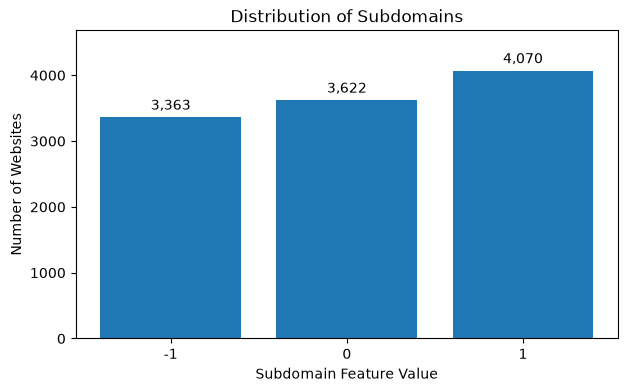

In [34]:
# Distribution of having_Sub_Domain

values = [-1, 0, 1]
counts = [df.filter(pl.col("having_Sub_Domain") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of Subdomains")
plt.xlabel("Subdomain Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()


#### The distribution of having_Sub_Domain is relatively balanced compared to the other features. There are 3,363 websites with a value of -1, 3,622 with a value of 0, and 4,070 with a value of 1. The mode is 1, although all three categories appear fairly frequently. Unlike some of the binary features, this feature includes a suspicious (0) category. There is no single category that heavily dominates the distribution, and traditional skewness and numerical outliers don't apply because the values are categorical. This is interesting because it shows that websites in the dataset have a variety of subdomain characteristics, which could be useful to investigate when looking at how phishing URLs attempt to appear legitimate.

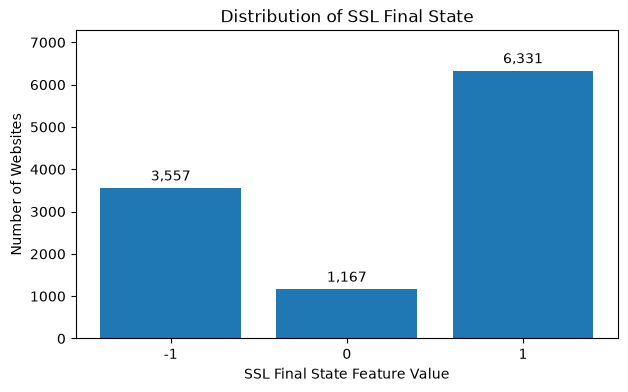

In [35]:
# Distribution of SSLfinal_State

values = [-1, 0, 1]
counts = [df.filter(pl.col("SSLfinal_State") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of SSL Final State")
plt.xlabel("SSL Final State Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()


#### The distribution of SSLfinal_State is concentrated at 1, with 6,331 websites in this category. There are also 3,557 websites with a value of -1 and 1,167 with a value of 0. The mode is 1, meaning legitimate-associated SSL characteristics are the most common. The distribution is unbalanced, with the suspicious category appearing the least frequently. This feature is particularly relevant to our research question because HTTPS and SSL certificates can influence how trustworthy a website appears, although having HTTPS alone does not guarantee that a website is legitimate.

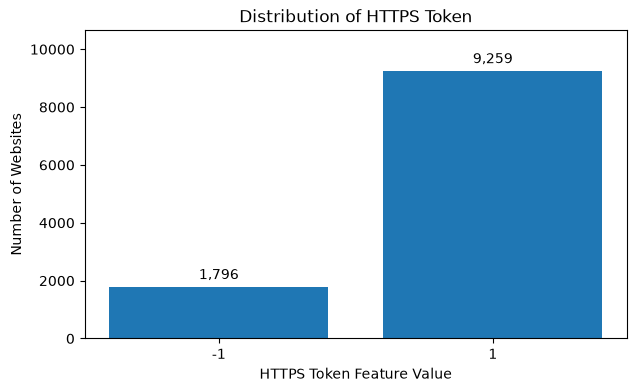

In [36]:
# Distribution of HTTPS_token

values = [-1, 1]
counts = [df.filter(pl.col("HTTPS_token") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of HTTPS Token")
plt.xlabel("HTTPS Token Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()

#### The distribution of HTTPS_token is heavily concentrated at 1, with 9,259 websites in this category compared to 1,796 at -1. The mode is 1, meaning most websites do not exhibit the phishing-associated HTTPS token characteristic. This feature is binary, so it only allows values of -1 and 1, with no 0 category. The distribution is unbalanced. This is relevant to our research question because attackers may include the word "HTTPS" in a domain name to make a website appear secure, even when it isn't legitimate.

## Relationships

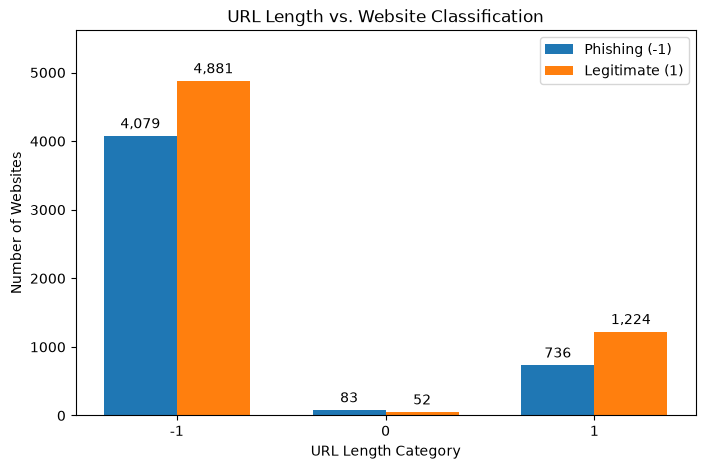

In [ ]:
# Plot 1 - Relationship between URL_Lengh and Result

counts = (
    df.group_by(["URL_Length", "Result"])
    .len()
    .sort(["URL_Length", "Result"])
)

values = [-1, 0, 1]

phishing_counts = [
    counts.filter(
        (pl.col("URL_Length") == v) & (pl.col("Result") == -1)
    )["len"].sum()
    for v in values
]

legitimate_counts = [
    counts.filter(
        (pl.col("URL_Length") == v) & (pl.col("Result") == 1)
    )["len"].sum()
    for v in values
]

import numpy as np

x = np.arange(len(values))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(x - width/2, phishing_counts, width, label="Phishing (-1)")
bars2 = plt.bar(x + width/2, legitimate_counts, width, label="Legitimate (1)")

plt.bar_label(bars1, labels=[f"{v:,}" for v in phishing_counts], padding=3)
plt.bar_label(bars2, labels=[f"{v:,}" for v in legitimate_counts], padding=3)

plt.xticks(x, [str(v) for v in values])
plt.title("URL Length vs. Website Classification")
plt.xlabel("URL Length Category")
plt.ylabel("Number of Websites")
plt.legend()

plt.margins(y=0.15)
plt.show()

In [41]:
df.group_by("URL_Length").agg(
    pl.len().alias("Total Websites"),
    (pl.col("Result") == -1).sum().alias("Phishing Websites"),
    ((pl.col("Result") == -1).mean() * 100)
        .round(2)
        .alias("Phishing Percentage")
).sort("URL_Length")

URL_Length,Total Websites,Phishing Websites,Phishing Percentage
i64,u32,u32,f64
-1,8960,4079,45.52
0,135,83,61.48
1,1960,736,37.55


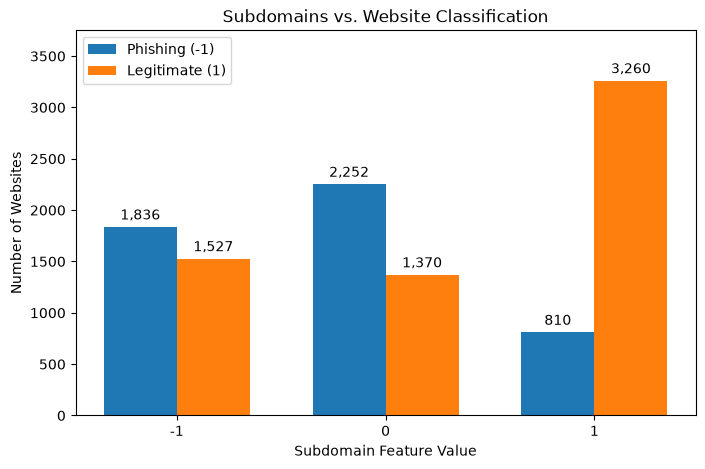

In [ ]:
# Plot 2 - Relationship between having_Sub_Domain and Result

counts = (
    df.group_by(["having_Sub_Domain", "Result"])
    .len()
    .sort(["having_Sub_Domain", "Result"])
)

values = [-1, 0, 1]

phishing_counts = [
    counts.filter(
        (pl.col("having_Sub_Domain") == v) & (pl.col("Result") == -1)
    )["len"].sum()
    for v in values
]

legitimate_counts = [
    counts.filter(
        (pl.col("having_Sub_Domain") == v) & (pl.col("Result") == 1)
    )["len"].sum()
    for v in values
]

x = np.arange(len(values))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(x - width/2, phishing_counts, width, label="Phishing (-1)")
bars2 = plt.bar(x + width/2, legitimate_counts, width, label="Legitimate (1)")

plt.bar_label(bars1, labels=[f"{v:,}" for v in phishing_counts], padding=3)
plt.bar_label(bars2, labels=[f"{v:,}" for v in legitimate_counts], padding=3)

plt.xticks(x, [str(v) for v in values])
plt.title("Subdomains vs. Website Classification")
plt.xlabel("Subdomain Feature Value")
plt.ylabel("Number of Websites")
plt.legend()

plt.margins(y=0.15)
plt.show()


In [42]:
df.group_by("having_Sub_Domain").agg(
    pl.len().alias("Total Websites"),
    (pl.col("Result") == -1).sum().alias("Phishing Websites"),
    ((pl.col("Result") == -1).mean() * 100)
        .round(2)
        .alias("Phishing Percentage")
).sort("having_Sub_Domain")

having_Sub_Domain,Total Websites,Phishing Websites,Phishing Percentage
i64,u32,u32,f64
-1,3363,1836,54.59
0,3622,2252,62.18
1,4070,810,19.9


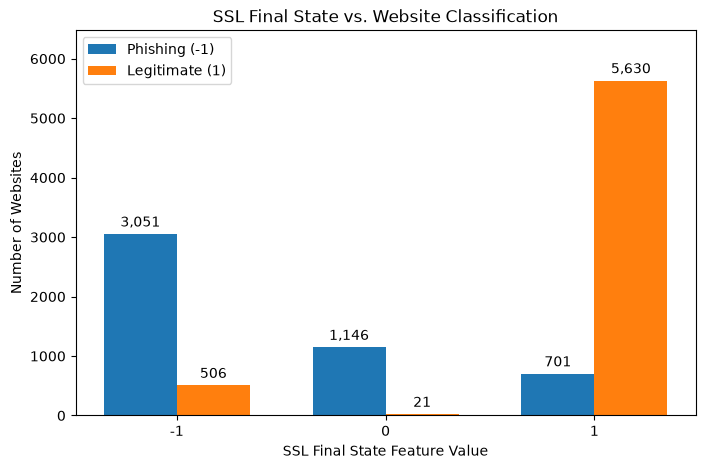

In [ ]:
# Plot 3 - Relationship between SSLfinal_State and Result

counts = (
    df.group_by(["SSLfinal_State", "Result"])
    .len()
    .sort(["SSLfinal_State", "Result"])
)

values = [-1, 0, 1]

phishing_counts = [
    counts.filter(
        (pl.col("SSLfinal_State") == v) & (pl.col("Result") == -1)
    )["len"].sum()
    for v in values
]

legitimate_counts = [
    counts.filter(
        (pl.col("SSLfinal_State") == v) & (pl.col("Result") == 1)
    )["len"].sum()
    for v in values
]

x = np.arange(len(values))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(x - width/2, phishing_counts, width, label="Phishing (-1)")
bars2 = plt.bar(x + width/2, legitimate_counts, width, label="Legitimate (1)")

plt.bar_label(bars1, labels=[f"{v:,}" for v in phishing_counts], padding=3)
plt.bar_label(bars2, labels=[f"{v:,}" for v in legitimate_counts], padding=3)

plt.xticks(x, [str(v) for v in values])
plt.title("SSL Final State vs. Website Classification")
plt.xlabel("SSL Final State Feature Value")
plt.ylabel("Number of Websites")
plt.legend()

plt.margins(y=0.15)
plt.show()


In [43]:
df.group_by("SSLfinal_State").agg(
    pl.len().alias("Total Websites"),
    (pl.col("Result") == -1).sum().alias("Phishing Websites"),
    ((pl.col("Result") == -1).mean() * 100)
        .round(2)
        .alias("Phishing Percentage")
).sort("SSLfinal_State")

SSLfinal_State,Total Websites,Phishing Websites,Phishing Percentage
i64,u32,u32,f64
-1,3557,3051,85.77
0,1167,1146,98.2
1,6331,701,11.07


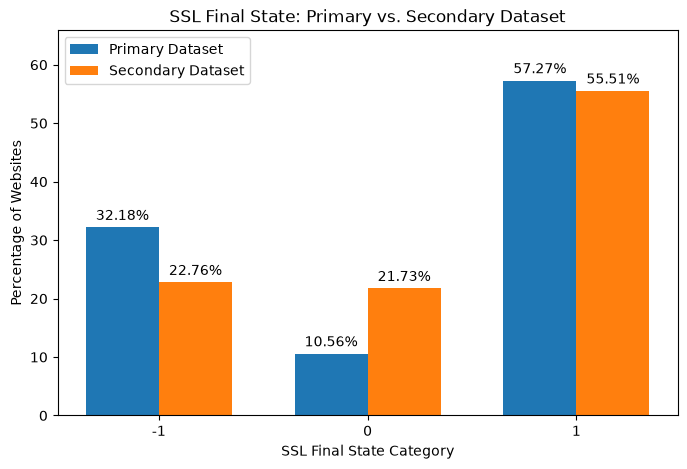

In [46]:
# Load the secondary dataset
with open("../datasets/website-phishing/PhishingData.arff", "r") as file:
    dataset2 = arff.load(file)

# Create the Polars DataFrame for the secondary dataset
column_names2 = [attribute[0] for attribute in dataset2["attributes"]]

df_secondary = pl.DataFrame(
    dataset2["data"],
    schema=column_names2,
    orient="row"
)

# Convert SSLfinal_State to an integer
df_secondary = df_secondary.with_columns(
    pl.col("SSLfinal_State").cast(pl.Int64)
)

# Compare SSLfinal_State across both datasets
values = [-1, 0, 1]

primary_percentages = [
    df.filter(pl.col("SSLfinal_State") == v).height / df.height * 100
    for v in values
]

secondary_percentages = [
    df_secondary.filter(pl.col("SSLfinal_State") == v).height / df_secondary.height * 100
    for v in values
]

# Set up the bar chart
x = np.arange(len(values))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(
    x - width/2,
    primary_percentages,
    width,
    label="Primary Dataset"
)

bars2 = plt.bar(
    x + width/2,
    secondary_percentages,
    width,
    label="Secondary Dataset"
)

# Display percentages above each bar
plt.bar_label(
    bars1,
    labels=[f"{v:.2f}%" for v in primary_percentages],
    padding=3
)

plt.bar_label(
    bars2,
    labels=[f"{v:.2f}%" for v in secondary_percentages],
    padding=3
)

plt.xticks(x, [str(v) for v in values])
plt.title("SSL Final State: Primary vs. Secondary Dataset")
plt.xlabel("SSL Final State Category")
plt.ylabel("Percentage of Websites")
plt.legend()

plt.margins(y=0.15)

plt.show()


### So what and what's next ? 
##### What each plot shows and why it matters for our research question. 

# Plot 1 – URL Length vs. Website Classification 

#### Looking at `URL_Length` compared to `Result`, the -1 category had the largest number of phishing websites (4,079), but the 0 category actually had the highest percentage of phishing websites at 61.48%. Meanwhile, 45.52% of websites whose URL lengths were categorized as phishing-associated (-1) were actually phishing, compared to 37.55% of websites whose URL lengths were categorized as legitimate-associated (1). This was somewhat unexpected because I thought the phishing-associated URL length category (-1) would have the highest phishing percentage. It's also interesting that 736 websites with legitimate-associated URL lengths were still classified as phishing. This matters to our research question because it shows that phishing websites can have normal-looking URL lengths, so URL length alone isn't enough to determine whether a website is phishing.

##### This makes me wonder whether phishing websites with normal-looking URL lengths also have other legitimate-looking characteristics, such as legitimate-associated SSL characteristics or simpler subdomain structures. A next step could be to compare URL_Length with SSLfinal_State or having_Sub_Domain, specifically among websites where Result = -1, to see whether multiple legitimate-looking characteristics appear together.

# Plot 2 - Subdomains vs. Website Classification

#### Looking at `having_Sub_Domain` compared to `Result`, the 0 category had the highest percentage of phishing websites at 62.18%, followed by the -1 category at 54.59%. Meanwhile, only 19.90% of websites with a value of 1 were phishing. Personally I think this is somewhat unexpected because I would have thought the -1 category would have the highest percentage of phishing websites rather than the suspicious (0) category. It's also interesting that 810 websites with legitimate-associated subdomain characteristics were still classified as phishing. This matters to our research question because it shows that phishing websites don't necessarily need suspicious-looking subdomains, and some may have simpler domain structures that appear legitimate. 

#### This makes me wonder whether phishing websites with normal-looking subdomains also have other legitimate-looking characteristics, such as a normal URL length or trusted SSL certificates. We could specifically look at phishing websites with having_Sub_Domain = 1 and compare their other features to see what characteristics they share.

# Plot 3 - SSL Final State vs. Website Classification

#### Looking at SSLfinal_State compared to Result, the 0 category had the highest percentage of phishing websites at 98.20%, followed by the -1 category at 85.77%. Meanwhile, only 11.07% of websites with a value of 1 were phishing. It makes sense that websites with legitimate-associated SSL characteristics have a much lower phishing percentage. What's especially interesting is that 701 phishing websites still had an SSLfinal_State value of 1. This matters to our research question because it suggests that phishing websites can have SSL characteristics associated with legitimate websites, meaning security indicators alone aren't enough to determine whether a website is phishing. A next step would be to investigate whether these websites also have normal-looking URL lengths, simple subdomain structures, or other characteristics that could make them appear legitimate. It would also be interesting to investigate how often phishing websites have multiple legitimate-associated features at the same time. How many of these features (like url_length, @ symbol, SSL final state, etc) are usually used together in order to carry out a successfull phishing attempt? I'm assuming too many of these features would make it look too suspicious for someone to click. Is there a sweet spot? 

# Plot 4 - SSL Final State: Primary vs. Secondary Dataset

#### Comparing SSLfinal_State across both datasets, the most common category in both is 1 (legitimate), with 57.27% of websites in the primary dataset and 55.51% in the secondary dataset falling into this category. However, the secondary dataset has a higher percentage of websites with a value of 0 (21.73%) compared to the primary dataset (10.56%). Meanwhile, the primary dataset has more websites with a value of -1 (32.18%) compared to the secondary dataset (22.76%). I thought the distributions might be more similar since both datasets include phishing-related website features, so the differences were somewhat unexpected. This matters to our research question because it shows how frequently different SSL characteristics appear in two separate datasets, although it doesn't tell us whether websites with these characteristics are actually phishing or whether people would find them convincing. It would be interesting to see whether the proportion of phishing websites with these characteristics is similar across both datasets. This could help us better understand whether SSL characteristics are useful for distinguishing phishing websites from legitimate ones, or whether phishing websites frequently share security characteristics with legitimate websites.

### Does our research question (Which features of phishing links and webpages make them harder for people to recognize?) need to be changed? 

##### I think our question does need to be revised. I don't think the direction needs to change but some revision would help. Our current question is worded in a way that makes it seem like we want to test/measure people's ability on recognizing phishing websites/urls. But neither this dataset nor our other primary and secondary datasets actually measure that, so I don't think we can answer that question directly.

#### Through this analysis I found that some phishing websites still have features typically associated with legitimate websites, such as normal-looking URL lengths, subdomain structures, and SSL characteristics. With this analysis I think that instead of focusing on whether people can recognize phishing websites, we should focus on the characteristics that phishing and legitimate websites have in common! We could change our questoin to "Which URL and webpage features are shared by both phishing and legitimate websites, potentially making them harder to distinguish?" 